# Household Energy Footprint

This notebook computes per-household and per-capita energy footprints from SHS 2019 data combined with sectoral energy intensities from `Energy_Model.py`.

**Workflow:**

1. **Cell 1** — Load (and cache) outputs from `Energy_Model.py`.
2. **Cell 1b** — Load the raw SHS 2019 SAS file (all variables).
3. **Cell 1c** — OECD-modified equivalence scale per household.
4. **Cell 1d** — Weighted income decile (`Inc_hh_dec`) added to `Unit_hh_cap`.
5. **Cell 2** — COICOP aggregation matrices (32 / 12 cat) + aggregation switch.
6. **Cell 3** — Per-household spend shares at the chosen aggregation.
7. **Cell 4** — Per-household-group EF tables (Total, per-hh, per-OECD-cap).
8. **Cell 5** — Stacked bar chart: TJ / OECD-cap and TJ / household.
9. **Cell 6** — Stacked bar chart: average TJ / household by province (PROV).
10. **Cell 7** — Stacked bar chart: average TJ / OECD-cap by household type (HHType6).
11. **Cell 8** — Stacked bar chart: average TJ / OECD-cap by reference-person age group (RP_AgeGrp).
12. **Cell 9** — Same chart, swept across 11 socio-demographic variables.
13. **Cell 10** — Stacked bar chart: average TJ / household by weighted income decile (Inc_hh_dec).

## Setup — imports and configuration

Override `DATA_DIR`, `FIGARO_FOLDER`, `COUNTRY_CODE`, `HH_CATEGORY`, or `FD_CATEGORIES` below. These values are forwarded to `Energy_Model.py` via `runpy.run_path(init_globals=...)`, so you do **not** need to edit `Energy_Model.py`.

A cache file (`_cache_household_ef_<hash>.pkl`) sits alongside the notebook; the hash is derived from the config, so each combination has its own cache and changes auto-invalidate.

In [1]:
import os
import pickle
import runpy
import hashlib
import json
import pandas as pd

# === Configuration ===
DATA_DIR = r"C:\Users\marta.baltruszewicz\OneDrive - Asplan Viak\Documents\additional_projects\Canada_hh_energy\Data"
FIGARO_FOLDER = r"C:\Users\marta.baltruszewicz\OneDrive - Asplan Viak\Documents - 403001-01 Utvikling og vedlikehold klimakost\General\Utslippsfaktorer\Kryssløpsanalyse\FIGARO data"
COUNTRY_CODE = "CA"
HH_CATEGORY = "P3_S14"
FD_CATEGORIES = ["P3_S13", "P3_S14", "P3_S15", "P51G", "P5M"]

_HERE = os.path.abspath(os.getcwd())
_ENERGY_MODEL_PATH = os.path.join(_HERE, "Energy_Model.py")
_ENERGY_MODEL_GLOBALS = {
    "DATA_DIR": DATA_DIR,
    "FIGARO_FOLDER": FIGARO_FOLDER,
    "COUNTRY_CODE": COUNTRY_CODE,
    "HH_CATEGORY": HH_CATEGORY,
    "FD_CATEGORIES": FD_CATEGORIES,
}
_config_hash = hashlib.md5(
    json.dumps(_ENERGY_MODEL_GLOBALS, sort_keys=True).encode()
).hexdigest()[:8]
_CACHE_PATH = os.path.join(_HERE, f"_cache_household_ef_{_config_hash}.pkl")
print(f"Cache file: {_CACHE_PATH}")

Cache file: c:\Users\marta.baltruszewicz\OneDrive - Asplan Viak\Documents\additional_projects\Canada_hh_energy\Git_Canada\Canada_HH_EF\_cache_household_ef_3e9b8914.pkl


## Cell 1 — Load Energy_Model results (cached)

Runs `Energy_Model.py` once, pickles the five outputs needed downstream, and on subsequent runs loads them instantly from the cache. The cache auto-invalidates when:

- Any of the Energy_Model source files (`Energy_Model.py`, `Figaro_economic_data.py`, etc.) is newer than the cache.
- Or the config in the Setup cell changes (different hash → different cache filename).

After loading, an `EF_tot_COICOP` column is added to `EF_COICOP_TJ_indir_dir` as `EF_indir_COICOP + EF_dir_COICOP`.

In [2]:
_SOURCE_FILES = [
    "Energy_Model.py",
    "Figaro_economic_data.py",
    "SHS_EDM_2019_data.py",
    "NACE_COICOP_mask.py",
    "RAS_balancing.py",
    "Indir_E_e.py",
]
_KEYS = [
    "e_COICOP_TJperMlnEur",
    "EF_COICOP_TJ_indir_dir",
    "SHS_2019_data_CAD_WGHT",
    "SHS_2019_data_Mln_EUR_WGHT",
    "NACE_to_COICOP_mask",
]


def _cache_is_fresh() -> bool:
    if not os.path.exists(_CACHE_PATH):
        return False
    cache_mtime = os.path.getmtime(_CACHE_PATH)
    for name in _SOURCE_FILES:
        path = os.path.join(_HERE, name)
        if os.path.exists(path) and os.path.getmtime(path) > cache_mtime:
            return False
    return True


if _cache_is_fresh():
    print("Loading cached Energy_Model outputs...")
    with open(_CACHE_PATH, "rb") as f:
        _data = pickle.load(f)
    print("Cache loaded.")
else:
    print("Cache missing or stale -- running Energy_Model.py (progress below)")
    print("-" * 70)
    _ns = runpy.run_path(
        _ENERGY_MODEL_PATH,
        run_name="__energy_model__",
        init_globals=_ENERGY_MODEL_GLOBALS,
    )
    print("-" * 70)
    _data = {k: _ns[k] for k in _KEYS}
    with open(_CACHE_PATH, "wb") as f:
        pickle.dump(_data, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"Cached {len(_KEYS)} objects to disk for future runs.")
    del _ns

e_COICOP_TJperMlnEur       = _data["e_COICOP_TJperMlnEur"]
EF_COICOP_TJ_indir_dir     = _data["EF_COICOP_TJ_indir_dir"]
SHS_2019_data_CAD_WGHT     = _data["SHS_2019_data_CAD_WGHT"]
SHS_2019_data_Mln_EUR_WGHT = _data["SHS_2019_data_Mln_EUR_WGHT"]
NACE_to_COICOP_mask        = _data["NACE_to_COICOP_mask"]
del _data

EF_COICOP_TJ_indir_dir["EF_tot_COICOP"] = (
    EF_COICOP_TJ_indir_dir["EF_indir_COICOP"] + EF_COICOP_TJ_indir_dir["EF_dir_COICOP"]
)

print(
    f"Ready: e_COICOP_TJperMlnEur {e_COICOP_TJperMlnEur.shape}, "
    f"EF_COICOP_TJ_indir_dir {EF_COICOP_TJ_indir_dir.shape}, "
    f"SHS_CAD {SHS_2019_data_CAD_WGHT.shape}, "
    f"SHS_EUR {SHS_2019_data_Mln_EUR_WGHT.shape}, "
    f"NACE_to_COICOP_mask {NACE_to_COICOP_mask.shape}"
)

Loading cached Energy_Model outputs...
Cache loaded.
Ready: e_COICOP_TJperMlnEur (75, 2), EF_COICOP_TJ_indir_dir (75, 3), SHS_CAD (7930, 77), SHS_EUR (7930, 77), NACE_to_COICOP_mask (62, 77)


## Cell 1b — Load raw (unweighted) SHS data

Reads the full SHS 2019 PUMF SAS file. No WeightD multiplication, no currency conversion — every column comes through as the raw SAS value. Stored as `SHS_2019_raw`.

In [3]:
_SAS_PATH = os.path.join(
    DATA_DIR,
    r"OneDrive_2026-03-09\Survey of Household Spending\SHS_EDM_2019\Data\SAS\pumf_shs2019.sas7bdat",
)
SHS_2019_raw = pd.read_sas(_SAS_PATH, format="sas7bdat", encoding="latin1")
print(f"SHS_2019_raw shape: {SHS_2019_raw.shape} (rows = households, cols = all SAS variables)")

SHS_2019_raw shape: (7930, 400) (rows = households, cols = all SAS variables)


## Cell 1c — OECD-modified equivalence scale

OECD-modified scale: **1.0** for the first adult, **+0.5** for each additional adult (15+), **+0.3** for each child (<15).

`HHType6` encoding:

| Code | Description | Adults | Children |
|---|---|---|---|
| 1 | One person | 1 | 0 |
| 2 | Couple without children | 2 | 0 |
| 3 | Couple with children | 2 | `HHSize − 2` (≤2) |
| 4 | Couple + other persons | 2 + extras | 1 if `P0TO4YN`/`P5TO15YN`=1 |
| 5 | Lone parent | 1 | `HHSize − 1` (≤3) |
| 6 | Other household | heuristic from presence flags | heuristic |

Because `HHSize` is capped at 4, kid counts are lower bounds (≤2 for couples-with-kids, ≤3 for lone parents).

Produces `Unit_hh_cap` with columns `CaseID`, `WeightD`, `OECD_scale`, `OECD_cap = WeightD × OECD_scale`.

In [4]:
def _oecd_scale_row(row):
    hht, hhs = row["HHType6"], row["HHSize"]
    if pd.isna(hht) or pd.isna(hhs):
        return float("nan")
    hht, hhs = int(hht), int(hhs)
    has_kid = (row.get("P0TO4YN") == 1) or (row.get("P5TO15YN") == 1)

    if hht == 1:
        n_adults, n_kids = 1, 0
    elif hht == 2:
        n_adults, n_kids = 2, 0
    elif hht == 3:
        n_adults, n_kids = 2, max(0, hhs - 2)
    elif hht == 4:
        n_adults = 2
        extras = max(0, hhs - 2)
        if has_kid and extras >= 1:
            n_kids = 1
            n_adults += extras - 1
        else:
            n_kids = 0
            n_adults += extras
    elif hht == 5:
        n_adults, n_kids = 1, max(0, hhs - 1)
    elif hht == 6:
        if has_kid:
            n_kids = 1
            n_adults = max(1, hhs - 1)
        else:
            n_kids = 0
            n_adults = max(1, hhs)
    else:
        n_adults, n_kids = 1, 0

    return 1.0 + 0.5 * (n_adults - 1) + 0.3 * n_kids


_oecd_scale = SHS_2019_raw.apply(_oecd_scale_row, axis=1)

Unit_hh_cap = pd.DataFrame({
    "CaseID":     SHS_2019_raw["CaseID"].values,
    "WeightD":    SHS_2019_raw["WeightD"].values,
    "OECD_scale": _oecd_scale.values,
})
Unit_hh_cap["OECD_cap"] = Unit_hh_cap["WeightD"] * Unit_hh_cap["OECD_scale"]

print(f"Unit_hh_cap shape: {Unit_hh_cap.shape}")
print(f"OECD_scale: mean={Unit_hh_cap['OECD_scale'].mean():.3f}, "
      f"min={Unit_hh_cap['OECD_scale'].min():.3f}, "
      f"max={Unit_hh_cap['OECD_scale'].max():.3f}, "
      f"NaN={Unit_hh_cap['OECD_scale'].isna().sum()}")
print(f"OECD_cap (sum): {Unit_hh_cap['OECD_cap'].sum():,.0f}")
print("OECD_scale distribution (top 10):")
print(Unit_hh_cap["OECD_scale"].value_counts().sort_index().head(10))

Unit_hh_cap shape: (7930, 4)
OECD_scale: mean=1.546, min=1.000, max=2.500, NaN=0
OECD_cap (sum): 22,918,298
OECD_scale distribution (top 10):
OECD_scale
1.0    2016
1.3     321
1.5    2774
1.6     158
1.8     823
1.9      69
2.0     200
2.1    1297
2.5     272
Name: count, dtype: int64


## Cell 1d — Weighted income decile (`Inc_hh_dec`)

Build a 1..10 decile assignment from the continuous `HH_TotInc` in `SHS_2019_raw`, weighted by `WeightD`. Each survey row's `WeightD` is treated as its mass, so the 10% / 20% / ... breakpoints are at the **weighted** cumulative distribution.

Cumulative-midpoint assignment is used: each row is placed at its own weight-midpoint inside the cumulative distribution. This avoids the edge bias a naive `floor(cumsum/total * 10)` approach would introduce (where rows near a breakpoint flip to the next decile based on tie-breaking).

`Inc_hh_dec` is then added to `Unit_hh_cap` so it's available alongside `WeightD` and `OECD_cap` for any downstream aggregation.

In [5]:
import numpy as np


def _weighted_decile(values, weights, n=10):
    """Return decile (1..n) per row using cumulative-midpoint quantile."""
    v = np.asarray(values, dtype=float)
    w = np.asarray(weights, dtype=float)
    order = np.argsort(v, kind="mergesort")
    cum_w = np.cumsum(w[order])
    total = cum_w[-1]
    cum_mid = cum_w - w[order] / 2.0
    decile_sorted = np.minimum(np.floor(cum_mid / total * n).astype(int) + 1, n)
    decile = np.empty_like(decile_sorted)
    decile[order] = decile_sorted
    return decile


_inc_dec_by_caseid = pd.Series(
    _weighted_decile(SHS_2019_raw["HH_TotInc"].values, SHS_2019_raw["WeightD"].values, n=10),
    index=SHS_2019_raw["CaseID"].values,
    name="Inc_hh_dec",
)
Unit_hh_cap["Inc_hh_dec"] = Unit_hh_cap["CaseID"].map(_inc_dec_by_caseid)

print("Inc_hh_dec distribution (count of survey rows per decile):")
print(Unit_hh_cap["Inc_hh_dec"].value_counts().sort_index())
print("Inc_hh_dec weighted population per decile:")
print(Unit_hh_cap.groupby("Inc_hh_dec")["WeightD"].sum().round(0))

Inc_hh_dec distribution (count of survey rows per decile):
Inc_hh_dec
1     623
2     784
3     807
4     851
5     774
6     824
7     848
8     823
9     798
10    798
Name: count, dtype: int64
Inc_hh_dec weighted population per decile:
Inc_hh_dec
1     1471017.0
2     1477163.0
3     1472642.0
4     1471361.0
5     1476127.0
6     1468302.0
7     1475656.0
8     1469628.0
9     1474920.0
10    1472684.0
Name: WeightD, dtype: float64


## Cell 2 — COICOP aggregation matrices + level switch

Loads two aggregation matrices from `COICOP_to_FIGARO_Bridge.xlsx` / tab `COICOP_to_COICOPaggr`:

- **`COICOP75_to_COICOP32`** — 32×75 (D25:BZ56, labels in C25:C56).
- **`COICOP75_to_COICOP12`** — 12×75 (D59:BZ70, labels in C59:C70).

Both share column headers from D8:BZ8 (the 75 detailed COICOP codes).

Set **`coicop_to_coicop_matching`** to `75` (no aggregation), `32`, or `12`. The switch aggregates both `SHS_2019_data_Mln_EUR_WGHT` and the total EF column into `SHS_aggr` and `EF_tot_aggr`.

In [6]:
_BRIDGE_PATH = os.path.join(DATA_DIR, "COICOP_to_FIGARO_Bridge.xlsx")
_BRIDGE_SHEET = "COICOP_to_COICOPaggr"


def _load_aggr_matrix(skiprows: int, nrows: int) -> pd.DataFrame:
    """Read one aggregation block: 'nrows' x 75 with labels in col C."""
    col_headers = (
        pd.read_excel(
            _BRIDGE_PATH, sheet_name=_BRIDGE_SHEET, usecols="D:BZ",
            header=None, skiprows=7, nrows=1,
        )
        .iloc[0].astype(str).str.strip().tolist()
    )
    df = pd.read_excel(
        _BRIDGE_PATH, sheet_name=_BRIDGE_SHEET, usecols="C:BZ",
        header=None, skiprows=skiprows, nrows=nrows,
    )
    df.index = df.iloc[:, 0].astype(str).str.strip()
    df = df.iloc[:, 1:].astype(float)
    df.columns = col_headers
    df.index.name = None
    df.columns.name = None
    return df


COICOP75_to_COICOP32 = _load_aggr_matrix(skiprows=24, nrows=32)
COICOP75_to_COICOP12 = _load_aggr_matrix(skiprows=58, nrows=12)
print(f"COICOP75_to_COICOP32 shape: {COICOP75_to_COICOP32.shape}")
print(f"COICOP75_to_COICOP12 shape: {COICOP75_to_COICOP12.shape}")

# === Switch: 75 (no aggregation), 32, or 12 ===
coicop_to_coicop_matching = 32

if coicop_to_coicop_matching == 75:
    _M = None
elif coicop_to_coicop_matching == 32:
    _M = COICOP75_to_COICOP32
elif coicop_to_coicop_matching == 12:
    _M = COICOP75_to_COICOP12
else:
    raise ValueError(
        f"coicop_to_coicop_matching must be 75, 32, or 12, got {coicop_to_coicop_matching!r}"
    )

_shs_75_vals = SHS_2019_data_Mln_EUR_WGHT.iloc[:, 2:]
if _M is None:
    SHS_aggr = SHS_2019_data_Mln_EUR_WGHT.copy()
    EF_tot_aggr = EF_COICOP_TJ_indir_dir["EF_tot_COICOP"].copy()
else:
    _M_aligned = _M[_shs_75_vals.columns]
    SHS_aggr_vals = _shs_75_vals @ _M_aligned.T
    SHS_aggr = SHS_aggr_vals.copy()
    SHS_aggr.insert(0, "WeightD", SHS_2019_data_Mln_EUR_WGHT["WeightD"].values)
    SHS_aggr.insert(0, "CaseID", SHS_2019_data_Mln_EUR_WGHT["CaseID"].values)
    EF_tot_aggr = _M_aligned @ EF_COICOP_TJ_indir_dir["EF_tot_COICOP"]
    EF_tot_aggr.name = "EF_tot_COICOP"

print(f"\ncoicop_to_coicop_matching = {coicop_to_coicop_matching}")
print(f"SHS_aggr shape:    {SHS_aggr.shape}")
print(f"EF_tot_aggr shape: {EF_tot_aggr.shape}, sum = {EF_tot_aggr.sum():,.2f} TJ")

COICOP75_to_COICOP32 shape: (32, 75)
COICOP75_to_COICOP12 shape: (12, 75)

coicop_to_coicop_matching = 32
SHS_aggr shape:    (7930, 34)
EF_tot_aggr shape: (32,), sum = 5,187,645.89 TJ


## Cell 3 — SHS spend shares per (aggregated) COICOP category

For each spending column, divide every household's value by the column total. Each column then sums to exactly 1 — a share-of-total-spend per category, per household. Operates on the aggregated SHS table from Cell 2.

In [7]:
SHS_spend_shares = SHS_aggr.iloc[:, 2:].div(SHS_aggr.iloc[:, 2:].sum(axis=0), axis=1)
SHS_spend_shares.insert(0, "CaseID", SHS_aggr["CaseID"].values)

print(f"SHS_spend_shares shape: {SHS_spend_shares.shape}")
col_sums = SHS_spend_shares.iloc[:, 1:].sum(axis=0)
print(f"Column sums (should all be ~1.0): min={col_sums.min():.6f}, max={col_sums.max():.6f}")
SHS_spend_shares.head()

SHS_spend_shares shape: (7930, 33)
Column sums (should all be ~1.0): min=1.000000, max=1.000000


,CaseID,01 – Food and non-alcoholic beverages,"02 – Alcoholic beverages, tobacco and narcotics",03 – Clothing and footwear,04.1 Actual rentals for housing,04.2 Imputed rentals for housing,04.3 Maintenance and repair of the dwelling,04.4 Water supply and miscellaneous services relating to the dwelling,"04.5 Electricity,",04.5 gas,...,09.4 Recreational and cultural services,"09.5 Newspapers, books and stationery",09.6 Package holidays,10 – Education,"11.1 Restaurants, cafés and the like",12.1 Personal care,12.4 Social protection,12.5 Insurance,12.6 Financial services,12.7 Other services n.e.c.
0,000010,0.000117,0.000103,0.000029,0.0,0.000006,0.000043,0.000427,0.000178,0.001031,...,0.000000e+00,0.000000,0.00000,0.000000,0.000000,0.000063,0.000000,0.000225,0.000000,1.937226e-04
1,000020,0.000019,0.000050,0.000030,0.0,0.000000,0.000129,0.000007,0.000017,0.000000,...,2.696666e-06,0.000020,0.00003,0.000000,0.000000,0.000005,0.000000,0.000018,0.000008,5.350457e-05
2,000030,0.000055,0.000000,0.000026,0.0,0.000086,0.000000,0.000018,0.000050,0.000000,...,4.895613e-07,0.000000,0.00000,0.000000,0.000008,0.000010,0.000000,0.000037,0.000005,3.402342e-06
3,000040,0.000457,0.000000,0.000594,0.0,0.001910,0.003779,0.000736,0.000460,0.002331,...,0.000000e+00,0.000207,0.00000,0.000143,0.000771,0.000407,0.000000,0.000174,0.000104,0.000000e+00
4,000050,0.000242,0.000331,0.000229,0.0,0.000714,0.000000,0.000210,0.000105,0.000151,...,6.982778e-03,0.000091,0.00000,0.000204,0.000241,0.000271,0.003327,0.000205,0.000143,3.190777e-07


## Cell 4 — Per-household-group energy footprint at the chosen COICOP level

Each SHS sample row represents a "household group" — one survey household standing in for `WeightD` population households. Three tables are produced, with the COICOP aggregation level encoded in the variable name (`xx` = 75 / 32 / 12):

- **`Total_EF_HHgrouped_TJ_xxCOICOP`** — Total energy footprint (TJ) per COICOP category for each household group. Each row value is the sum of EF for all population households the survey row represents: `SHS_spend_shares * EF_tot_aggr`.
- **`EF_per_hh_TJ_xxCOICOP`** — TJ per actual household = `Total_EF_HHgrouped / WeightD` (matched on CaseID from `Unit_hh_cap`).
- **`EF_per_OECDcap_TJ_xxCOICOP`** — TJ per OECD-equivalent adult = `Total_EF_HHgrouped / OECD_cap`.

All three keep `CaseID` as the first column. At the 75-COICOP level the indir/dir breakdown is also produced (`Dir_EF_hh_TJ`, `Indir_EF_hh_TJ`).

In [8]:
_n = coicop_to_coicop_matching
_shares = SHS_spend_shares.iloc[:, 1:]

# Per-group total (one row = one survey household, value already weighted).
_total = _shares.mul(EF_tot_aggr, axis=1)
_total.insert(0, "CaseID", SHS_spend_shares["CaseID"].values)

# Align WeightD and OECD_cap to CaseID for safety.
_uhc = Unit_hh_cap.set_index("CaseID")
_w = _uhc["WeightD"].reindex(_total["CaseID"]).values
_c = _uhc["OECD_cap"].reindex(_total["CaseID"]).values

_per_hh = _total.iloc[:, 1:].div(_w, axis=0)
_per_hh.insert(0, "CaseID", _total["CaseID"].values)

_per_cap = _total.iloc[:, 1:].div(_c, axis=0)
_per_cap.insert(0, "CaseID", _total["CaseID"].values)

# Expose under dynamic names that include the aggregation level.
globals()[f"Total_EF_HHgrouped_TJ_{_n}COICOP"] = _total
globals()[f"EF_per_hh_TJ_{_n}COICOP"]          = _per_hh
globals()[f"EF_per_OECDcap_TJ_{_n}COICOP"]     = _per_cap

print(f"Total_EF_HHgrouped_TJ_{_n}COICOP shape: {_total.shape}, "
      f"total = {_total.iloc[:, 1:].values.sum():,.2f} TJ")
print(f"EF_per_hh_TJ_{_n}COICOP        shape: {_per_hh.shape}")
print(f"EF_per_OECDcap_TJ_{_n}COICOP   shape: {_per_cap.shape}")

if coicop_to_coicop_matching == 75:
    Dir_EF_hh_TJ   = _shares.mul(EF_COICOP_TJ_indir_dir["EF_dir_COICOP"],   axis=1)
    Indir_EF_hh_TJ = _shares.mul(EF_COICOP_TJ_indir_dir["EF_indir_COICOP"], axis=1)
    Dir_EF_hh_TJ.insert(0, "CaseID", SHS_spend_shares["CaseID"].values)
    Indir_EF_hh_TJ.insert(0, "CaseID", SHS_spend_shares["CaseID"].values)
    print(f"Dir_EF_hh_TJ   shape: {Dir_EF_hh_TJ.shape},   total = {Dir_EF_hh_TJ.iloc[:, 1:].values.sum():,.2f} TJ")
    print(f"Indir_EF_hh_TJ shape: {Indir_EF_hh_TJ.shape}, total = {Indir_EF_hh_TJ.iloc[:, 1:].values.sum():,.2f} TJ")

Total_EF_HHgrouped_TJ_32COICOP shape: (7930, 33), total = 5,187,645.89 TJ
EF_per_hh_TJ_32COICOP        shape: (7930, 33)
EF_per_OECDcap_TJ_32COICOP   shape: (7930, 33)


## Cell 5 — Stacked bar chart

Two bars (per OECD-cap, per household), each **stacked by COICOP category**. Largest contributors at the bottom. Long category labels are truncated to 25 chars for the legend.

- `EF_per_OECD_cap = EF_tot_aggr / sum(OECD_cap)` — TJ per OECD-equivalent adult.
- `EF_per_hh       = EF_tot_aggr / sum(WeightD)` — TJ per household.

sum(OECD_cap) = 22,918,298
sum(WeightD)  = 14,729,500
EF total: 5,187,646 TJ -> 0.226 TJ/OECD-cap, 0.352 TJ/hh


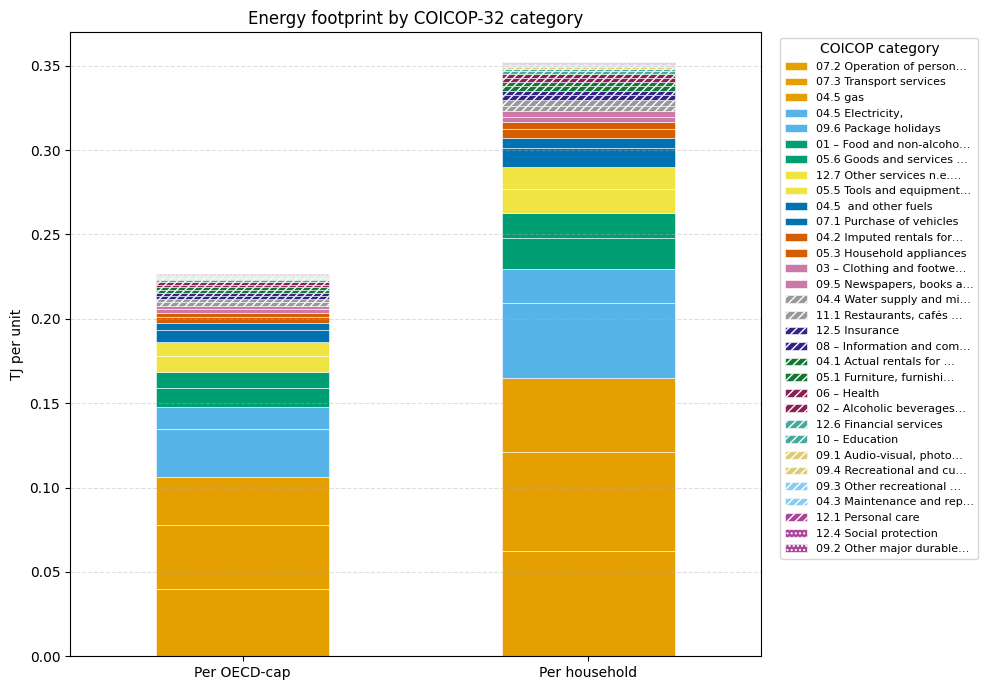

In [9]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Colourblind-friendly categorical palette (Okabe-Ito 8 + Paul Tol "muted" 7).
# Tested for deuteranopia, protanopia and tritanopia. The colormap cycles if
# there are more categories than colors (use 12-COICOP for cleanest result).
_COLORBLIND_PALETTE = [
    "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2",
    "#D55E00", "#CC79A7", "#999999", "#332288", "#117733",
    "#882255", "#44AA99", "#DDCC77", "#88CCEE", "#AA4499",
]
_CB_CMAP = ListedColormap(_COLORBLIND_PALETTE, name="cb15")

_CB_HATCHES = ("", "////", "....", "xxxx")


def _add_hatching(ax, palette_size=len(_COLORBLIND_PALETTE), hatches=_CB_HATCHES):
    """Add hatch patterns to stacked-bar segments past palette_size so cycled
    colours become distinguishable. Works after df.plot.bar(stacked=True)."""
    for i, container in enumerate(ax.containers):
        hatch = hatches[(i // palette_size) % len(hatches)]
        if hatch:
            for patch in container:
                patch.set_hatch(hatch)
    leg = ax.get_legend()
    if leg is None:
        return
    handles = getattr(leg, "legend_handles", None) or getattr(leg, "legendHandles", [])
    for i, handle in enumerate(handles):
        hatch = hatches[(i // palette_size) % len(hatches)]
        if hatch:
            handle.set_hatch(hatch)



_sum_OECD_cap = Unit_hh_cap["OECD_cap"].sum()
_sum_WeightD  = Unit_hh_cap["WeightD"].sum()

EF_per_OECD_cap = (EF_tot_aggr / _sum_OECD_cap).sort_values(ascending=False)
EF_per_hh       = EF_tot_aggr.reindex(EF_per_OECD_cap.index) / _sum_WeightD

print(f"sum(OECD_cap) = {_sum_OECD_cap:,.0f}")
print(f"sum(WeightD)  = {_sum_WeightD:,.0f}")
print(f"EF total: {EF_tot_aggr.sum():,.0f} TJ "
      f"-> {EF_per_OECD_cap.sum():.3f} TJ/OECD-cap, "
      f"{EF_per_hh.sum():.3f} TJ/hh")


def _short(label, n=25):
    s = str(label).strip()
    return s if len(s) <= n else s[: n - 1] + "…"


plot_df = pd.DataFrame({
    "Per OECD-cap": EF_per_OECD_cap,
    "Per household": EF_per_hh,
}).T
plot_df.columns = [_short(c) for c in plot_df.columns]

fig, ax = plt.subplots(figsize=(10, 7))
plot_df.plot.bar(
    ax=ax, stacked=True, color=_COLORBLIND_PALETTE, edgecolor="white", linewidth=0.4
)
ax.set_title(f"Energy footprint by COICOP-{coicop_to_coicop_matching} category")
ax.set_ylabel("TJ per unit")
ax.set_xlabel("")
ax.tick_params(axis="x", labelrotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="COICOP category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
_add_hatching(ax)
plt.tight_layout()
plt.show()

## Cell 6 — Stacked bar by province (PROV)

Group households by `PROV` (from `SHS_2019_raw`) and compute the weight-average TJ per household per COICOP category:

`avg_TJ_per_hh[prov, cat] = sum(Total_EF_hh_TJ[h, cat] for h in prov) / sum(WeightD[h] for h in prov)`

Each bar = one province, stacked by COICOP category. Standard Canadian PROV codes are mapped to two-letter abbreviations (NL, QC, ON, …) for readability.

EF_per_hh_by_PROV shape: (11, 32)
             07.2 Operation of personal transport equipment  \
NL                                                   0.0663   
PE                                                   0.0696   
NS                                                   0.0674   
NB                                                   0.0812   
QC                                                   0.0552   
ON                                                   0.0636   
MB                                                   0.0662   
SK                                                   0.0804   
AB                                                   0.0607   
BC                                                   0.0635   
Territories                                          0.0682   

             07.3 Transport services  04.5 Electricity,  \
NL                            0.0439             0.0776   
PE                            0.0357             0.0558   
NS                            0.

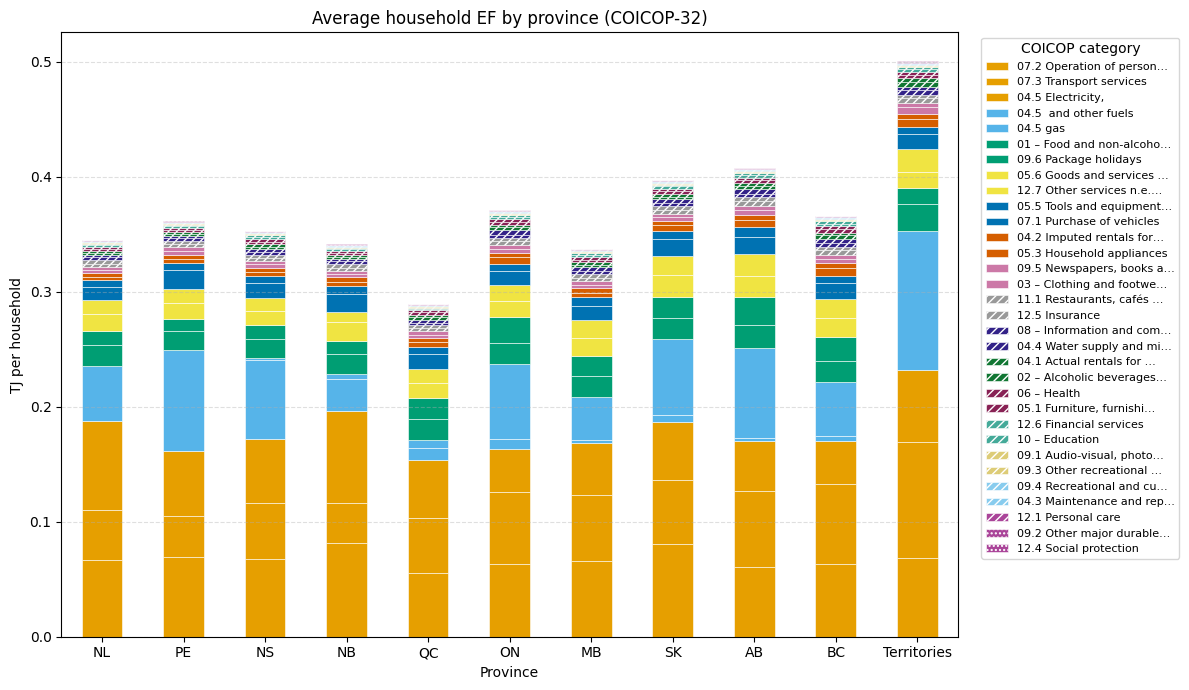

In [10]:
_PROV_NAMES = {
    "10": "NL", "11": "PE", "12": "NS", "13": "NB",
    "24": "QC", "35": "ON",
    "46": "MB", "47": "SK", "48": "AB", "59": "BC",
    "63": "Territories",   # YT+NT+NU bundled in PUMF for confidentiality
}

_total_df = globals()[f"Total_EF_HHgrouped_TJ_{coicop_to_coicop_matching}COICOP"]
_meta_prov = SHS_2019_raw[["CaseID", "Prov", "WeightD"]]
_merged = _total_df.merge(_meta_prov, on="CaseID", how="inner")

_cat_cols = [c for c in _total_df.columns if c != "CaseID"]
_grp = _merged.groupby("Prov")
EF_per_hh_by_PROV = _grp[_cat_cols].sum().div(_grp["WeightD"].sum(), axis=0)

# Sort columns by total contribution so largest stacks at the bottom.
_col_order = EF_per_hh_by_PROV.sum(axis=0).sort_values(ascending=False).index
EF_per_hh_by_PROV = EF_per_hh_by_PROV[_col_order]

# Pretty province labels (fall back to raw code if unknown). Prov is stored
# as a string like "10", "24", ...
EF_per_hh_by_PROV.index = [
    _PROV_NAMES.get(str(p).strip(), str(p).strip()) for p in EF_per_hh_by_PROV.index
]

print(f"EF_per_hh_by_PROV shape: {EF_per_hh_by_PROV.shape}")
print(EF_per_hh_by_PROV.round(4))

fig, ax = plt.subplots(figsize=(12, 7))
EF_per_hh_by_PROV.rename(columns=_short).plot.bar(
    ax=ax, stacked=True, color=_COLORBLIND_PALETTE, edgecolor="white", linewidth=0.4
)
ax.set_title(f"Average household EF by province (COICOP-{coicop_to_coicop_matching})")
ax.set_ylabel("TJ per household")
ax.set_xlabel("Province")
ax.tick_params(axis="x", labelrotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="COICOP category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
_add_hatching(ax)
plt.tight_layout()
plt.show()

## Cell 7 — Stacked bar by household type (HHType6)

Group households by `HHType6` (from `SHS_2019_raw`) and compute the **OECD_cap-weighted mean** of `EF_per_OECDcap_TJ_xxCOICOP`:

`avg[hht, c] = sum_h(EF_per_OECDcap[h, c] × OECD_cap[h]) / sum_h(OECD_cap[h])`

This gives TJ per OECD-equivalent adult, averaged across the **people** in households of that type (rather than across survey rows). Each bar = one household-type, stacked by COICOP category.

HHType6 codes:
- 1: One person
- 2: Couple, no kids
- 3: Couple with kids
- 4: Couple + others
- 5: Lone parent
- 6: Other household

EF_per_OECDcap_by_HHType6 shape: (6, 32)
                  07.2 Operation of personal transport equipment  \
One person                                                0.0308   
Couple, no kids                                           0.0435   
Couple with kids                                          0.0447   
Couple + others                                           0.0445   
Lone parent                                               0.0402   
Other household                                           0.0263   

                  07.3 Transport services  04.5 gas  04.5 Electricity,  \
One person                         0.0324    0.0244             0.0272   
Couple, no kids                    0.0385    0.0287             0.0329   
Couple with kids                   0.0394    0.0309             0.0277   
Couple + others                    0.0430    0.0296             0.0255   
Lone parent                        0.0314    0.0273             0.0282   
Other household                    0.0

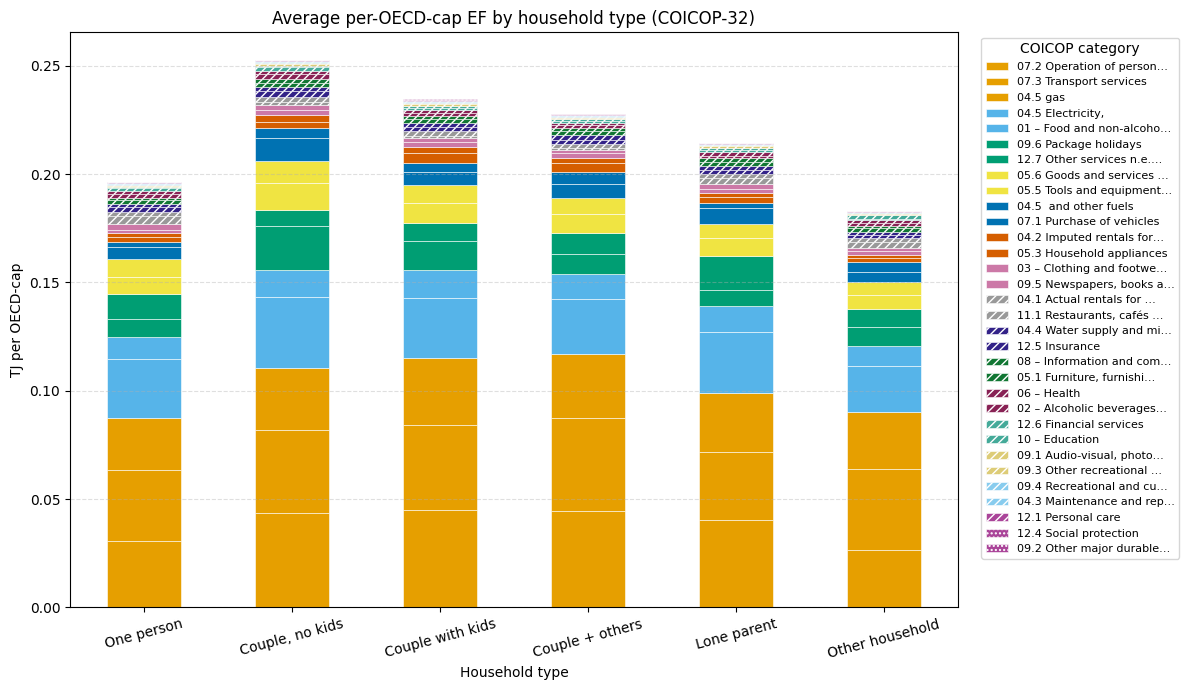

In [11]:
_HHTYPE_NAMES = {
    1: "One person",
    2: "Couple, no kids",
    3: "Couple with kids",
    4: "Couple + others",
    5: "Lone parent",
    6: "Other household",
}

_n = coicop_to_coicop_matching
_per_cap_df = globals()[f"EF_per_OECDcap_TJ_{_n}COICOP"]

_meta_h = SHS_2019_raw[["CaseID", "HHType6"]].merge(
    Unit_hh_cap[["CaseID", "OECD_cap"]], on="CaseID", how="inner"
)
_merged = _per_cap_df.merge(_meta_h, on="CaseID", how="inner")
_cat_cols = [c for c in _per_cap_df.columns if c != "CaseID"]

# OECD_cap-weighted mean per HHType6.
_weighted = _merged[_cat_cols].multiply(_merged["OECD_cap"], axis=0)
_weighted["HHType6"] = _merged["HHType6"].values
EF_per_OECDcap_by_HHType6 = (
    _weighted.groupby("HHType6").sum()
    .div(_merged.groupby("HHType6")["OECD_cap"].sum(), axis=0)
)

# Sort columns by total contribution so largest stacks at the bottom.
_col_order = EF_per_OECDcap_by_HHType6.sum(axis=0).sort_values(ascending=False).index
EF_per_OECDcap_by_HHType6 = EF_per_OECDcap_by_HHType6[_col_order]

# Pretty household-type labels (fall back to raw code if unknown).
EF_per_OECDcap_by_HHType6.index = [
    _HHTYPE_NAMES.get(int(t), str(int(t))) for t in EF_per_OECDcap_by_HHType6.index
]

print(f"EF_per_OECDcap_by_HHType6 shape: {EF_per_OECDcap_by_HHType6.shape}")
print(EF_per_OECDcap_by_HHType6.round(4))

fig, ax = plt.subplots(figsize=(12, 7))
EF_per_OECDcap_by_HHType6.rename(columns=_short).plot.bar(
    ax=ax, stacked=True, color=_COLORBLIND_PALETTE, edgecolor="white", linewidth=0.4
)
ax.set_title(f"Average per-OECD-cap EF by household type (COICOP-{coicop_to_coicop_matching})")
ax.set_ylabel("TJ per OECD-cap")
ax.set_xlabel("Household type")
ax.tick_params(axis="x", labelrotation=15)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="COICOP category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
_add_hatching(ax)
plt.tight_layout()
plt.show()

## Cell 8 — Stacked bar by reference-person age (RP_AgeGrp)

Same OECD_cap-weighted-mean method as Cell 7, but grouped by `RP_AgeGrp` (age of the household reference person). Bars are kept in numeric age order on the x-axis.

PUMF age-group codes:
- `"01"`: <30
- `"02"`: 30-39
- `"03"`: 40-54
- `"04"`: 55-64
- `"05"`: 65-74
- `"06"`: 75+

EF_per_OECDcap_by_RPAgeGrp shape: (6, 32)
       07.2 Operation of personal transport equipment  \
<30                                            0.0312   
30-39                                          0.0365   
40-54                                          0.0448   
55-64                                          0.0474   
65-74                                          0.0380   
75+                                            0.0270   

       07.3 Transport services  04.5 Electricity,  04.5 gas  \
<30                     0.0450             0.0202    0.0156   
30-39                   0.0390             0.0232    0.0235   
40-54                   0.0425             0.0288    0.0307   
55-64                   0.0389             0.0318    0.0329   
65-74                   0.0290             0.0318    0.0304   
75+                     0.0207             0.0327    0.0312   

       09.6 Package holidays  01 – Food and non-alcoholic beverages  \
<30                   0.0049                 

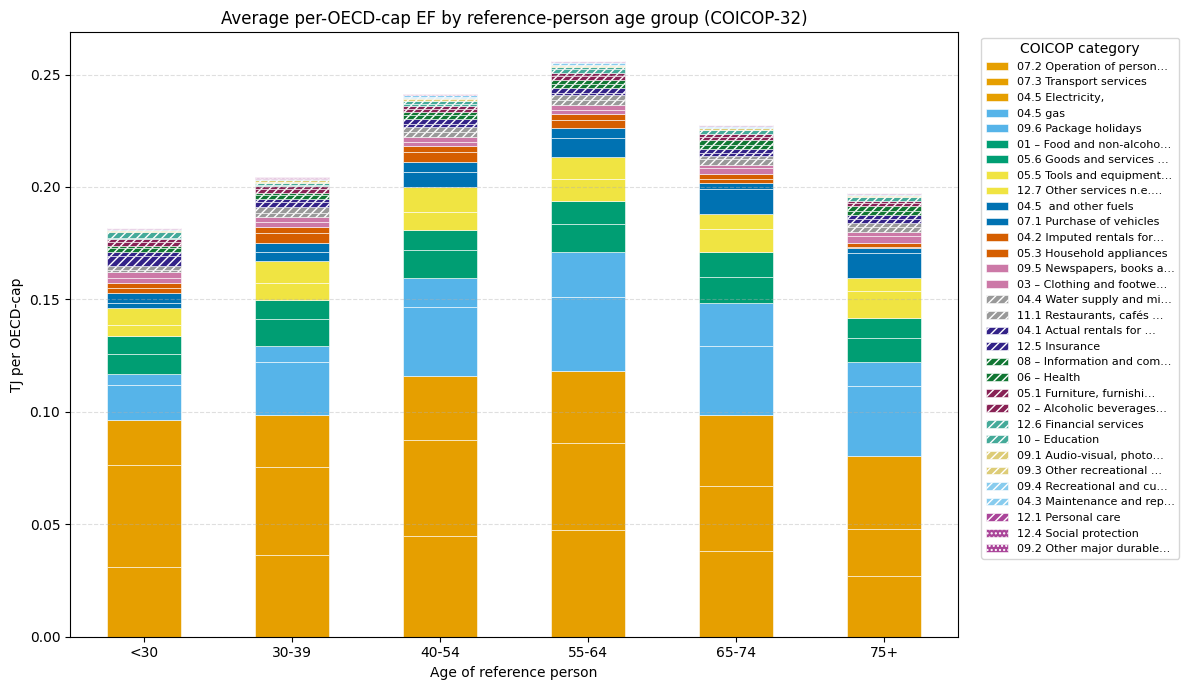

In [12]:
_RP_AGE_NAMES = {
    "01": "<30",
    "02": "30-39",
    "03": "40-54",
    "04": "55-64",
    "05": "65-74",
    "06": "75+",
}

_per_cap_df = globals()[f"EF_per_OECDcap_TJ_{coicop_to_coicop_matching}COICOP"]

_meta_a = SHS_2019_raw[["CaseID", "RP_AgeGrp"]].merge(
    Unit_hh_cap[["CaseID", "OECD_cap"]], on="CaseID", how="inner"
)
_merged = _per_cap_df.merge(_meta_a, on="CaseID", how="inner")
_cat_cols = [c for c in _per_cap_df.columns if c != "CaseID"]

# OECD_cap-weighted mean per RP_AgeGrp.
_weighted = _merged[_cat_cols].multiply(_merged["OECD_cap"], axis=0)
_weighted["RP_AgeGrp"] = _merged["RP_AgeGrp"].values
EF_per_OECDcap_by_RPAgeGrp = (
    _weighted.groupby("RP_AgeGrp").sum()
    .div(_merged.groupby("RP_AgeGrp")["OECD_cap"].sum(), axis=0)
)

# Sort columns by total contribution so largest stacks at the bottom.
_col_order = EF_per_OECDcap_by_RPAgeGrp.sum(axis=0).sort_values(ascending=False).index
EF_per_OECDcap_by_RPAgeGrp = EF_per_OECDcap_by_RPAgeGrp[_col_order]

# Pretty age-group labels (preserve numeric order on the x-axis).
EF_per_OECDcap_by_RPAgeGrp = EF_per_OECDcap_by_RPAgeGrp.sort_index()
EF_per_OECDcap_by_RPAgeGrp.index = [
    _RP_AGE_NAMES.get(str(a).strip(), str(a).strip()) for a in EF_per_OECDcap_by_RPAgeGrp.index
]

print(f"EF_per_OECDcap_by_RPAgeGrp shape: {EF_per_OECDcap_by_RPAgeGrp.shape}")
print(EF_per_OECDcap_by_RPAgeGrp.round(4))

fig, ax = plt.subplots(figsize=(12, 7))
EF_per_OECDcap_by_RPAgeGrp.rename(columns=_short).plot.bar(
    ax=ax, stacked=True, color=_COLORBLIND_PALETTE, edgecolor="white", linewidth=0.4
)
ax.set_title(
    f"Average per-OECD-cap EF by reference-person age group "
    f"(COICOP-{coicop_to_coicop_matching})"
)
ax.set_ylabel("TJ per OECD-cap")
ax.set_xlabel("Age of reference person")
ax.tick_params(axis="x", labelrotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="COICOP category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
_add_hatching(ax)
plt.tight_layout()
plt.show()

## Cell 9 — Per-OECD-cap EF by additional SHS variables

Sweep the same OECD_cap-weighted-mean method across a list of socio-demographic SHS variables, producing one stacked bar chart per variable. The math and styling are factored into a helper (`_plot_ef_by`) so adding more variables is a one-line edit.

Variables plotted (with their SHS PUMF code → label mapping):

| Variable | Description |
|---|---|
| `RP_Gender` | Reference-person gender |
| `RP_MarStat` | Reference-person marital status |
| `RP_Educ` | Reference-person education |
| `DwelTyp` | Dwelling type |
| `Tenure` | Owner / Renter / Other |
| `NumBedr` | Number of bedrooms |
| `SecResYN` | Has secondary residence |
| `OthPropYN` | Has other property |
| `InternetYN` | Has internet at home |
| `VehicleYN` | Has vehicle |
| `HH_MajIncSrc` | Major household income source (note: requested as `HH_ManIncSrc`, the actual PUMF variable is `HH_MajIncSrc`) |

Results are also captured in `_results_by_var` (dict of DataFrames, one per column) if you want to inspect or export them.

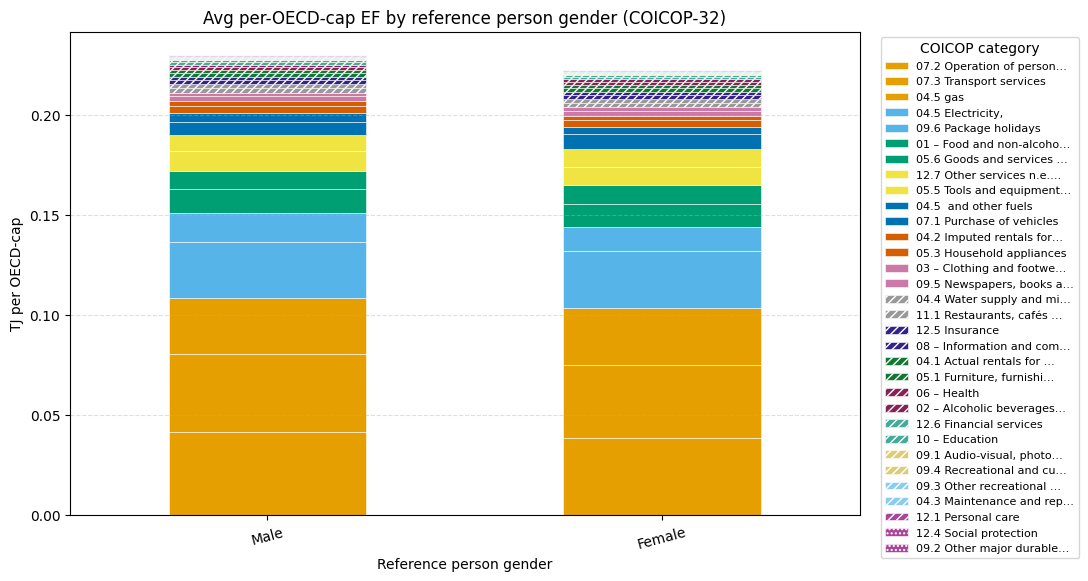

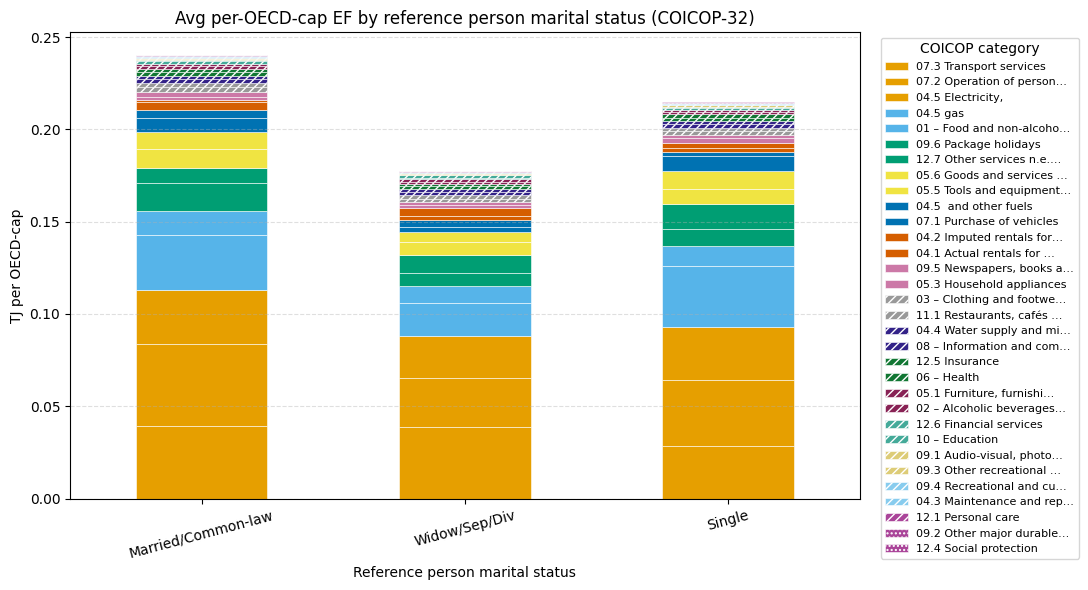

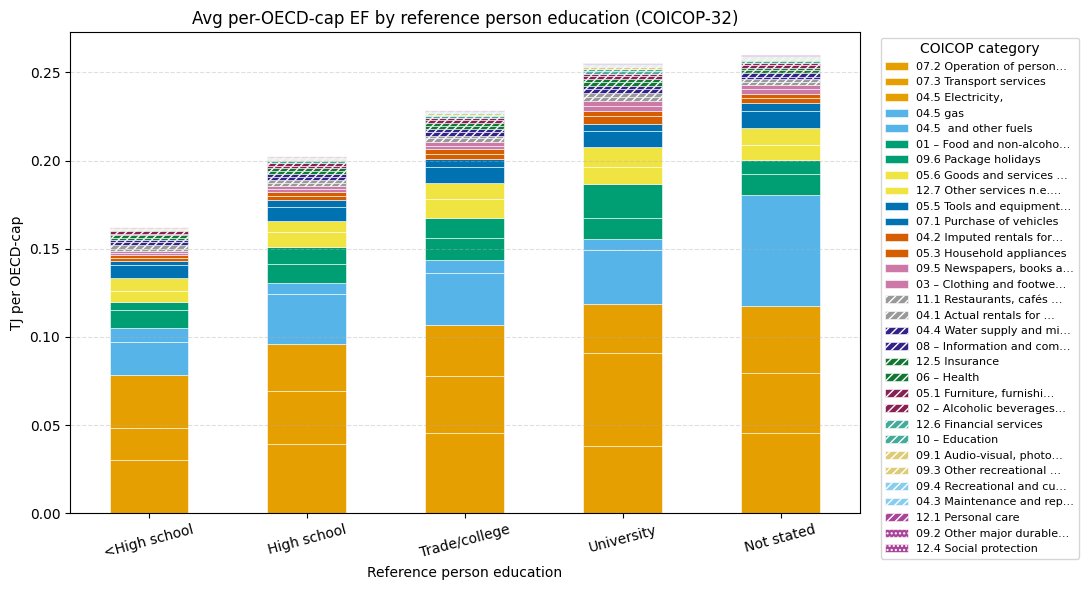

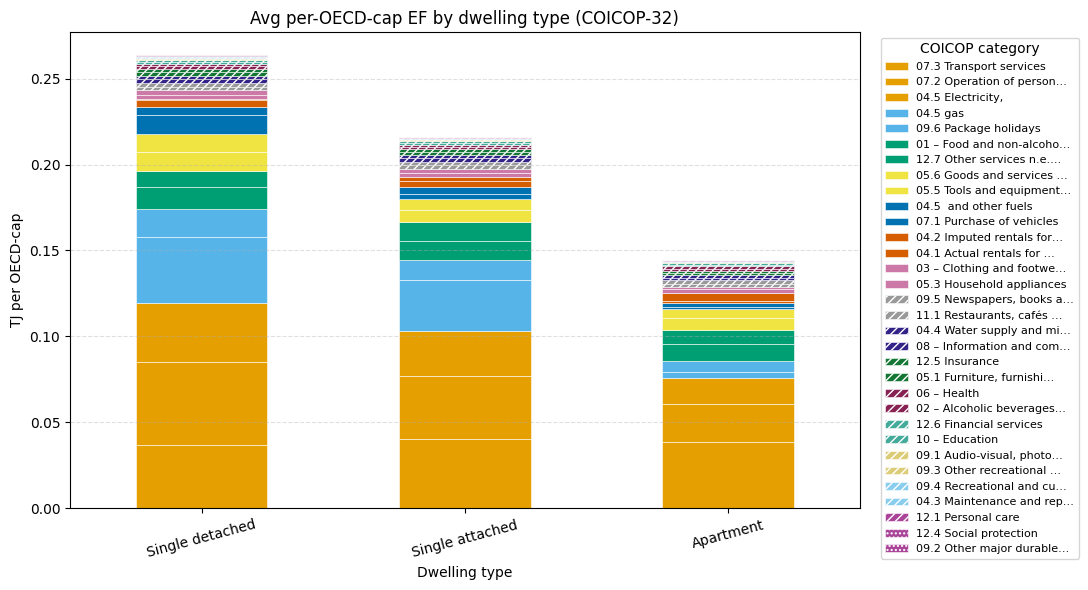

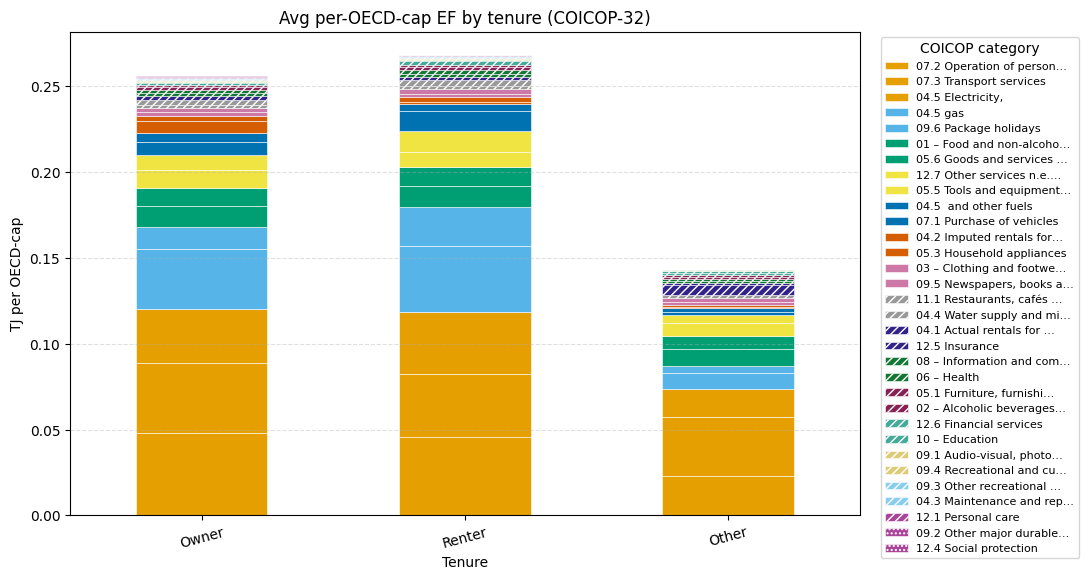

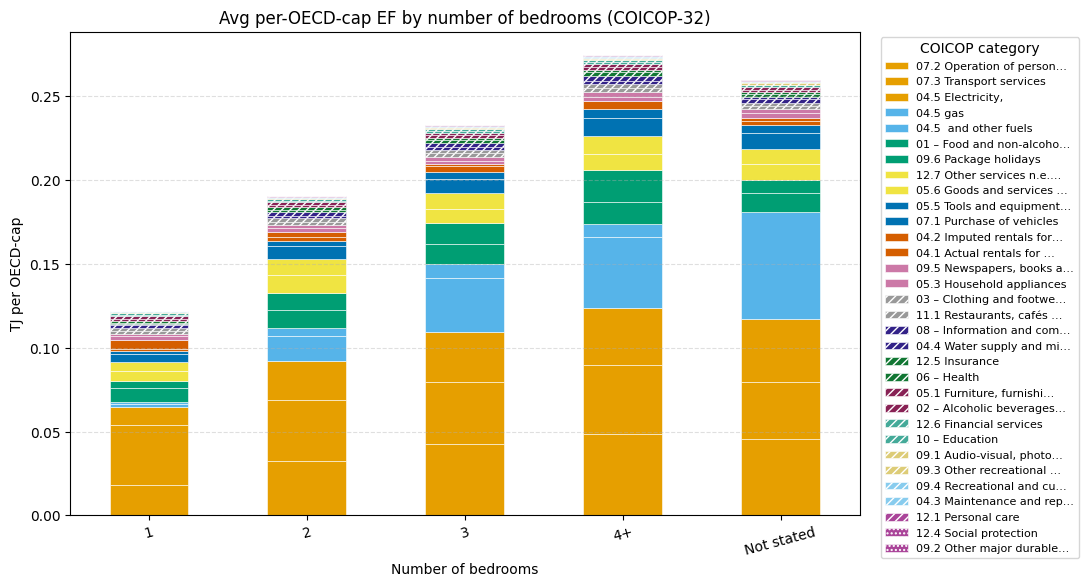

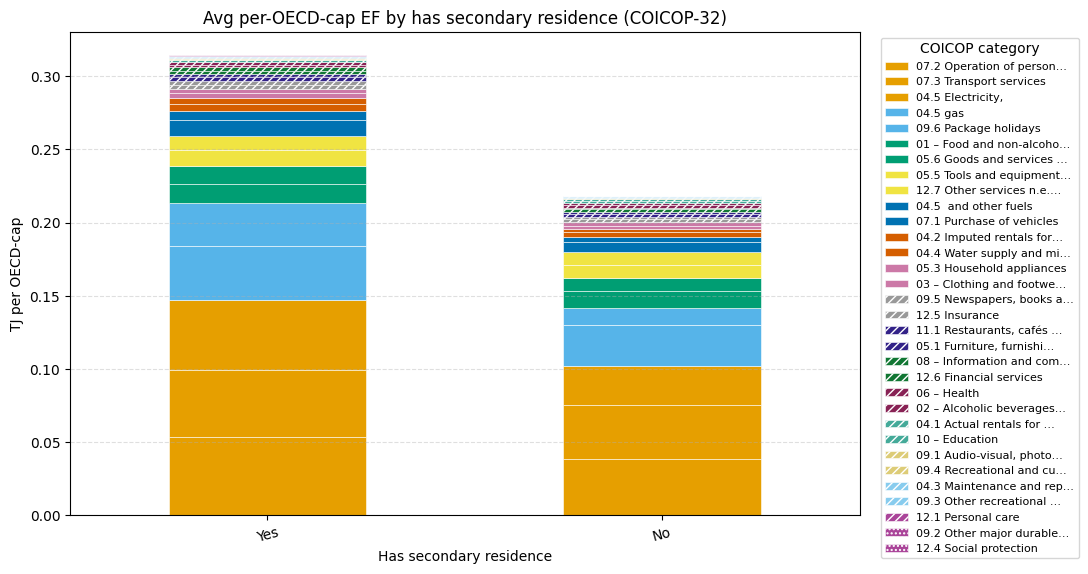

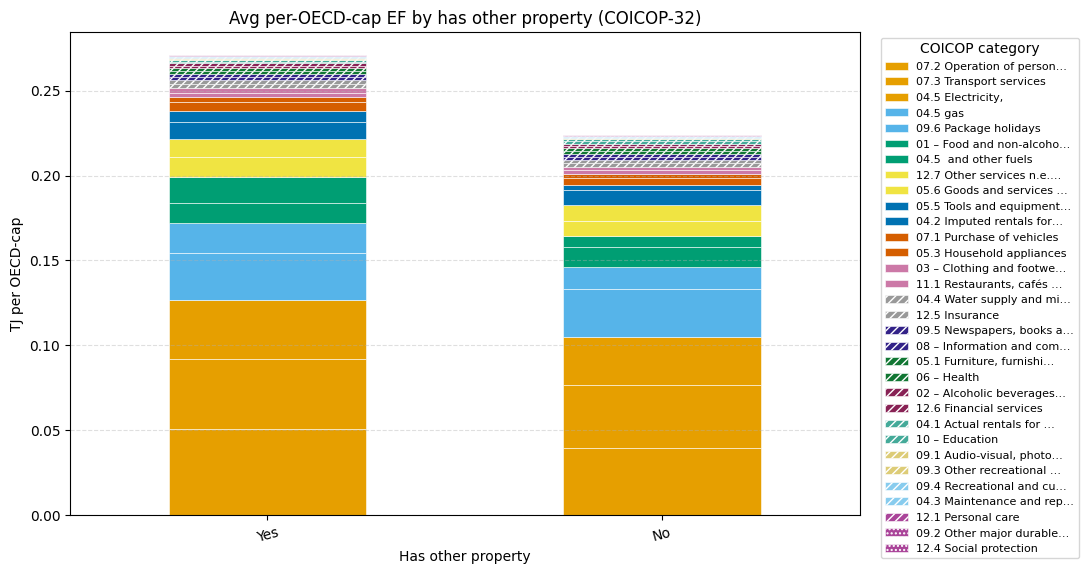

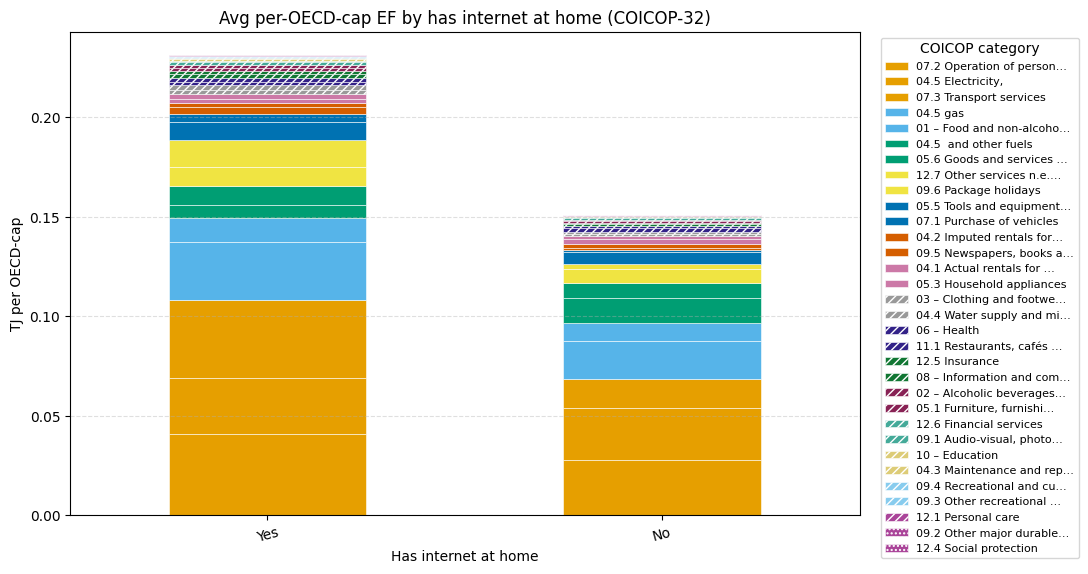

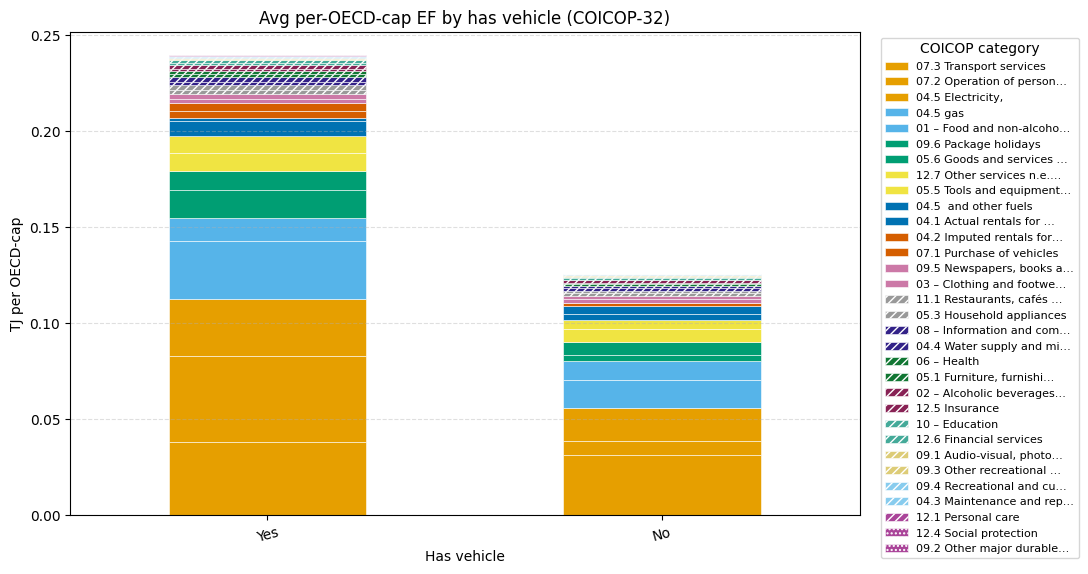

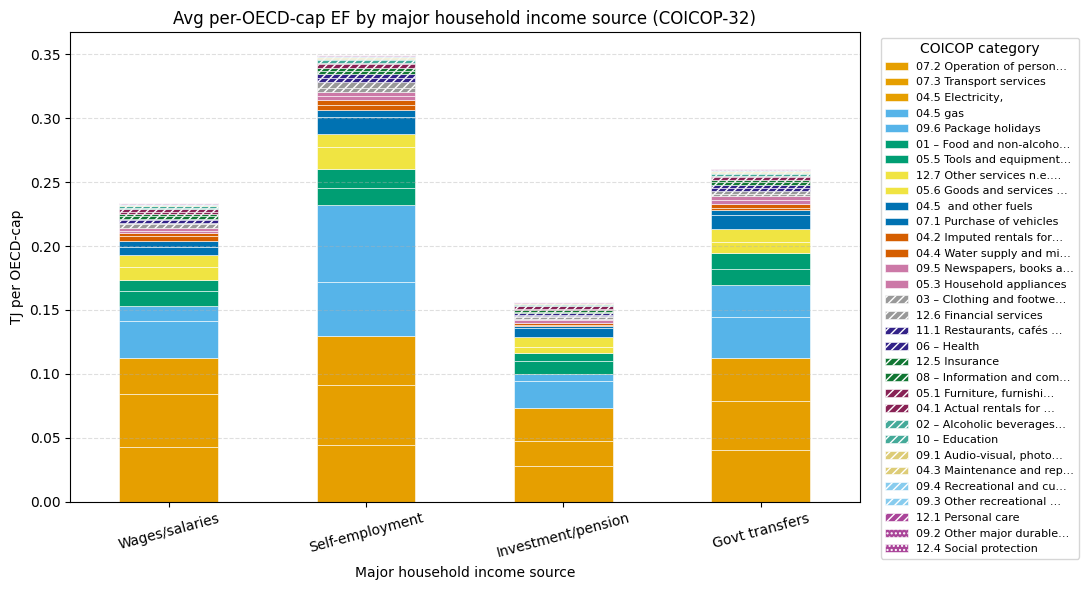

In [13]:
_VAR_SPECS = {
    "RP_Gender":   ({"1": "Male", "2": "Female"},
                    "Reference person gender", False),
    "RP_MarStat":  ({"1": "Married/Common-law", "2": "Widow/Sep/Div", "3": "Single"},
                    "Reference person marital status", False),
    "RP_Educ":     ({"1": "<High school", "2": "High school", "3": "Trade/college",
                     "4": "University", "9": "Not stated"},
                    "Reference person education", True),
    "DwelTyp":     ({"1": "Single detached", "2": "Single attached", "3": "Apartment"},
                    "Dwelling type", False),
    "Tenure":      ({"1": "Owner", "2": "Renter", "3": "Other"},
                    "Tenure", False),
    "NumBedr":     ({"1": "1", "2": "2", "3": "3", "4": "4+", "9": "Not stated"},
                    "Number of bedrooms", True),
    "SecResYN":    ({"1": "Yes", "2": "No"},
                    "Has secondary residence", False),
    "OthPropYN":   ({"1": "Yes", "2": "No"},
                    "Has other property", False),
    "InternetYN":  ({"1": "Yes", "2": "No"},
                    "Has internet at home", False),
    "VehicleYN":   ({"1": "Yes", "2": "No"},
                    "Has vehicle", False),
    "HH_MajIncSrc": ({"1": "Wages/salaries", "2": "Self-employment",
                      "3": "Investment/pension", "4": "Govt transfers"},
                     "Major household income source", False),
}

_per_cap_df = globals()[f"EF_per_OECDcap_TJ_{coicop_to_coicop_matching}COICOP"]
_cat_cols = [c for c in _per_cap_df.columns if c != "CaseID"]


def _plot_ef_by(col, labels_map, x_label, sort_by_index):
    """OECD_cap-weighted mean of EF_per_OECDcap per category of `col`."""
    meta = SHS_2019_raw[["CaseID", col]].merge(
        Unit_hh_cap[["CaseID", "OECD_cap"]], on="CaseID", how="inner"
    )
    merged = _per_cap_df.merge(meta, on="CaseID", how="inner")
    weighted = merged[_cat_cols].multiply(merged["OECD_cap"], axis=0)
    weighted[col] = merged[col].values
    result = (
        weighted.groupby(col).sum()
        .div(merged.groupby(col)["OECD_cap"].sum(), axis=0)
    )
    # Stack largest COICOP contributors at the bottom (same order across charts).
    col_order = result.sum(axis=0).sort_values(ascending=False).index
    result = result[col_order]
    if sort_by_index:
        result = result.sort_index()
    # Pretty x-axis labels.
    result.index = [labels_map.get(str(v).strip(), str(v).strip()) for v in result.index]

    fig, ax = plt.subplots(figsize=(11, 6))
    result.rename(columns=_short).plot.bar(
        ax=ax, stacked=True, color=_COLORBLIND_PALETTE, edgecolor="white", linewidth=0.4
    )
    ax.set_title(
        f"Avg per-OECD-cap EF by {x_label.lower()} (COICOP-{coicop_to_coicop_matching})"
    )
    ax.set_ylabel("TJ per OECD-cap")
    ax.set_xlabel(x_label)
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend(title="COICOP category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    _add_hatching(ax)
    plt.tight_layout()
    plt.show()
    return result


_results_by_var = {}
for _col, (_labels, _xlabel, _sort_idx) in _VAR_SPECS.items():
    if _col not in SHS_2019_raw.columns:
        print(f"Skipping {_col} (not in SHS_2019_raw)")
        continue
    _results_by_var[_col] = _plot_ef_by(_col, _labels, _xlabel, _sort_idx)

## Cell 10 — Stacked bar by weighted income decile (Inc_hh_dec)

Aggregate `Total_EF_HHgrouped_TJ_xxCOICOP` (the per-survey-row weighted footprint) by `Inc_hh_dec` (built in Cell 1d) and divide by the sum of `WeightD` to get the **average TJ per household** in each decile.

### How `avg_TJ_per_hh` is calculated

**1. What's in `Total_EF_HHgrouped_TJ_xxCOICOP`?**

Each row represents one SHS survey household standing in for `WeightD` similar population households. The TJ value is **already weighted** — it's the sum of energy footprints for all `WeightD` households the survey row represents. So if `WeightD = 200`, the value is 200× the footprint of a single household.

**2. From "group total TJ" to "average per household"**

Within an income decile (or any group), numerator and denominator are both summed across the survey rows in that group:

| Term | Meaning |
|---|---|
| `sum_h Total_EF[h, c]` | Total energy footprint (TJ) for **all** population households in the decile |
| `sum_h WeightD[h]`     | Total number of population households in the decile |

So the ratio:

`avg_TJ_per_hh[dec, c] = sum_h(Total_EF[h, c]) / sum_h(WeightD[h])`

reads as:

`avg_TJ_per_hh = (TJ for everyone in the decile) / (number of households in the decile)`

i.e. the **population-mean TJ per actual household** in that decile.

### Tiny worked example

Say 3 survey rows fall into decile D5 for some COICOP category:

| CaseID | Total_EF (TJ) | WeightD (= hh represented) |
|---|---|---|
| A | 6,000 | 200 |
| B | 3,000 | 100 |
| C | 1,500 |  50 |

- `sum(Total_EF)` = 10,500 TJ — total footprint across all 350 population households in D5.
- `sum(WeightD)` = 350 households.
- `avg_TJ_per_hh` = 10,500 / 350 = **30 TJ per household**.

If you randomly pick one of the 350 households in this decile, the expected EF is 30 TJ for this COICOP category.

### Why this is "WeightD-weighted" without explicitly multiplying

Each survey row already contains `WeightD × single-household-EF`, so summing those values is equivalent to a `WeightD`-weighted sum of single-household values. Dividing by `sum(WeightD)` then gives the weighted mean — exactly the population average.

Bars are labeled `D1` (lowest income) through `D10` (highest income), stacked by COICOP category with the largest contributor at the bottom.

EF_per_hh_by_IncDec shape: (10, 32)
Weighted mean HH_TotInc per decile (CAD):
Inc_hh_dec
1      14508.0
2      28697.0
3      41323.0
4      55339.0
5      69387.0
6      84430.0
7     103796.0
8     125932.0
9     158435.0
10    247641.0
dtype: float64
            07.2 Operation of personal transport equipment  \
D1\n$15k                                            0.0244   
D2\n$29k                                            0.0362   
D3\n$41k                                            0.0409   
D4\n$55k                                            0.0497   
D5\n$69k                                            0.0575   
D6\n$84k                                            0.0723   
D7\n$104k                                           0.0743   
D8\n$126k                                           0.0837   
D9\n$158k                                           0.0854   
D10\n$248k                                          0.0992   

            07.3 Transport services  04.5 gas  04.5 Electricity

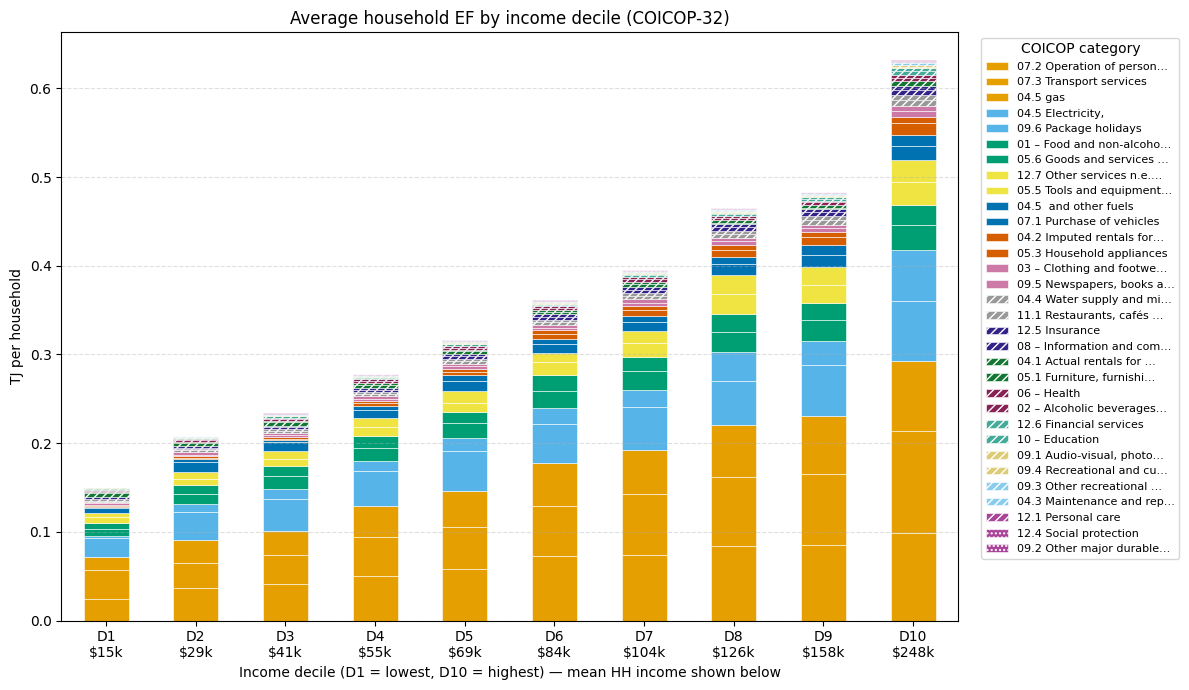

In [14]:
_total_df = globals()[f"Total_EF_HHgrouped_TJ_{coicop_to_coicop_matching}COICOP"]
_meta_d = Unit_hh_cap[["CaseID", "Inc_hh_dec", "WeightD"]]
_merged = _total_df.merge(_meta_d, on="CaseID", how="inner")
_cat_cols = [c for c in _total_df.columns if c != "CaseID"]

_grp = _merged.groupby("Inc_hh_dec")
EF_per_hh_by_IncDec = _grp[_cat_cols].sum().div(_grp["WeightD"].sum(), axis=0)

# Sort COICOP columns by total contribution; keep deciles in numeric order.
_col_order = EF_per_hh_by_IncDec.sum(axis=0).sort_values(ascending=False).index
EF_per_hh_by_IncDec = EF_per_hh_by_IncDec[_col_order].sort_index()

# Weighted mean income (HH_TotInc, CAD) per decile, for x-tick annotation:
#   mean_inc[dec] = sum_h(HH_TotInc[h] * WeightD[h]) / sum_h(WeightD[h])
_inc_meta = SHS_2019_raw[["CaseID", "HH_TotInc"]].merge(
    Unit_hh_cap[["CaseID", "Inc_hh_dec", "WeightD"]], on="CaseID", how="inner"
)
mean_inc_per_IncDec = (
    (_inc_meta["HH_TotInc"] * _inc_meta["WeightD"])
    .groupby(_inc_meta["Inc_hh_dec"]).sum()
    .div(_inc_meta.groupby("Inc_hh_dec")["WeightD"].sum())
).sort_index()

# Two-line x-tick labels: "D1\n$24k" etc.
EF_per_hh_by_IncDec.index = [
    f"D{int(d)}\n${mean_inc_per_IncDec.loc[d] / 1000:.0f}k"
    for d in EF_per_hh_by_IncDec.index
]

print(f"EF_per_hh_by_IncDec shape: {EF_per_hh_by_IncDec.shape}")
print("Weighted mean HH_TotInc per decile (CAD):")
print(mean_inc_per_IncDec.round(0))
print(EF_per_hh_by_IncDec.round(4))

fig, ax = plt.subplots(figsize=(12, 7))
EF_per_hh_by_IncDec.rename(columns=_short).plot.bar(
    ax=ax, stacked=True, color=_COLORBLIND_PALETTE, edgecolor="white", linewidth=0.4
)
ax.set_title(f"Average household EF by income decile (COICOP-{coicop_to_coicop_matching})")
ax.set_ylabel("TJ per household")
ax.set_xlabel("Income decile (D1 = lowest, D10 = highest) — mean HH income shown below")
ax.tick_params(axis="x", labelrotation=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="COICOP category", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
_add_hatching(ax)
plt.tight_layout()
plt.show()